# Evaluación Parcial 2: Comparación entre MLP y CNN para Patologías en Tomate

**Asignatura:** Técnicas Avanzadas de Machine Learning (TLY1102)

**Sección:** 001D

**Integrantes:**
- Matías Gutiérrez
- David Larenas
- Victor Mena

## Fase 0: Comprensión del Negocio

Para este trabajo mantenemos la misma variante de la EP1: usamos solo imágenes de hojas de tomate y dejamos fuera papa y pimentón. La razón es la misma de antes: el tomate concentra la mayor cantidad de enfermedades del dataset y eso nos permite comparar dos arquitecturas sobre un problema acotado.

La diferencia con la EP1 es que ahora no buscamos solo clasificar, sino comparar un MLP con una CNN. Para que la comparación sea justa, usamos los mismos datos, el mismo split, el mismo preprocesamiento y el mismo protocolo de entrenamiento. La CNN debería aprovechar mejor la estructura espacial de la imagen; el MLP, al aplanarla, pierde esa información.

Nuestro objetivo es medir esa diferencia con accuracy, F1 macro, matrices de confusión, mapas de características y Grad-CAM, y reconocer las limitaciones de ambos modelos.

## Fase 1: Carga y Preparación de Datos

### Descompresión del Dataset

Como el dataset viene comprimido, lo descomprimimos en `/content/data`. En Colab el archivo debe estar en `/content/PlantVillage Dataset.zip`.

In [1]:
!unzip -o -q "/content/PlantVillage Dataset.zip" -d "/content/data"

### Importaciones de Librerias

Usamos TensorFlow y Keras para los modelos, y scikit-learn, matplotlib y seaborn para las métricas y los gráficos.

In [2]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_DIR = Path('./data')
MODELS_DIR = Path('./models')
IMAGES_DIR = Path('./images')
MODELS_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

I0000 00:00:1792766063.521923  114396 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792766064.289702  114396 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Carga de Dataset

Usamos las mismas 10 clases de tomate de la EP1. Ahora hacemos un split estratificado 80/10/10: 80% para entrenar, 10% para validar y 10% para test. Guardamos el manifiesto en `data/split.csv` para que el split no cambie entre ejecuciones ni entre local y Colab.

In [3]:
DATA_ROOT = Path('./data/PlantVillage')

clases_variante = [
    'Tomato_Bacterial_spot',
    'Tomato_Early_blight',
    'Tomato_Late_blight',
    'Tomato_Leaf_Mold',
    'Tomato_Septoria_leaf_spot',
    'Tomato_Spider_mites_Two_spotted_spider_mite',
    'Tomato__Target_Spot',
    'Tomato__Tomato_YellowLeaf__Curl_Virus',
    'Tomato__Tomato_mosaic_virus',
    'Tomato_healthy'
]

registros = []
for clase in clases_variante:
    for archivo in (DATA_ROOT / clase).iterdir():
        if archivo.suffix.lower() in {'.jpg', '.jpeg', '.png'}:
            registros.append({
                'filepath': str(archivo.relative_to(DATA_ROOT)),
                'label': clase
            })

registros.sort(key=lambda r: (r['label'], r['filepath']))
df = pd.DataFrame(registros)
df['y'] = df['label'].map({clase: i for i, clase in enumerate(clases_variante)})
df['abs_path'] = df['filepath'].map(lambda ruta: str(DATA_ROOT / ruta))

train_df, temp_df = train_test_split(
    df, test_size=0.2, stratify=df['label'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=SEED
)

df['split'] = 'train'
df.loc[val_df.index, 'split'] = 'val'
df.loc[test_df.index, 'split'] = 'test'

df[['filepath', 'label', 'split']].to_csv(DATA_DIR / 'split.csv', index=False)
with open(DATA_DIR / 'class_names.json', 'w') as f:
    json.dump(clases_variante, f, indent=2)

def cargar_imagen(ruta, etiqueta):
    imagen = tf.io.read_file(ruta)
    imagen = tf.io.decode_image(imagen, channels=3, expand_animations=False)
    imagen = tf.image.resize(imagen, IMG_SIZE)
    return tf.cast(imagen, tf.float32), etiqueta

def crear_dataset(split, entrenamiento=False):
    datos = df[df['split'] == split]
    ds = tf.data.Dataset.from_tensor_slices(
        (datos['abs_path'].values, datos['y'].values)
    )
    if entrenamiento:
        ds = ds.shuffle(len(datos), seed=SEED)
    return ds.map(cargar_imagen, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = crear_dataset('train', entrenamiento=True)
val_ds = crear_dataset('val')
test_ds = crear_dataset('test')
clases = clases_variante

print(df['split'].value_counts())
print('Lotes de train:', len(train_ds))
print('Lotes de validación:', len(val_ds))
print('Lotes de test:', len(test_ds))

split
train    12808
test      1602
val       1601
Name: count, dtype: int64
Lotes de train: 401
Lotes de validación: 51
Lotes de test: 51


### Gráfico del Balance de las Clases del Dataset

Revisamos cuántas imágenes hay por clase en entrenamiento. El dataset está desbalanceado, así que además de accuracy vamos a mirar el F1 macro.

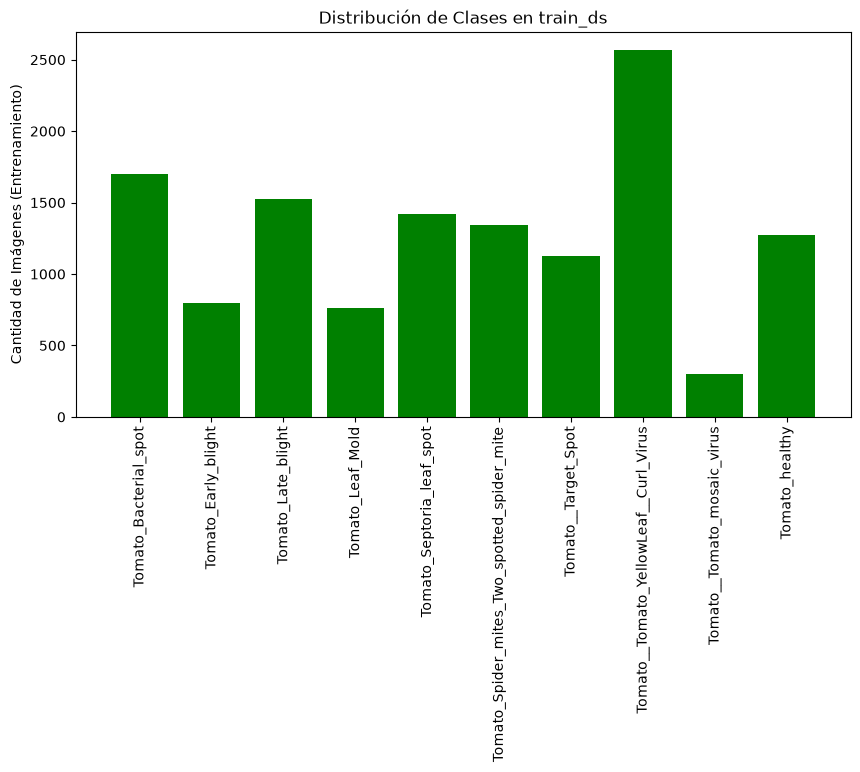

In [4]:
etiquetas = np.concatenate([y.numpy() for x, y in train_ds])
_, image_counts = np.unique(etiquetas, return_counts=True)

plt.figure(figsize=(10, 5))
plt.bar(clases, image_counts, color='green')
plt.xticks(rotation=90)
plt.ylabel('Cantidad de Imágenes (Entrenamiento)')
plt.title('Distribución de Clases en train_ds')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'balance_clases.png', dpi=150, bbox_inches='tight')
plt.show()

### Visualización de Muestras

Mostramos algunas imágenes para confirmar que la carga y las etiquetas están bien.

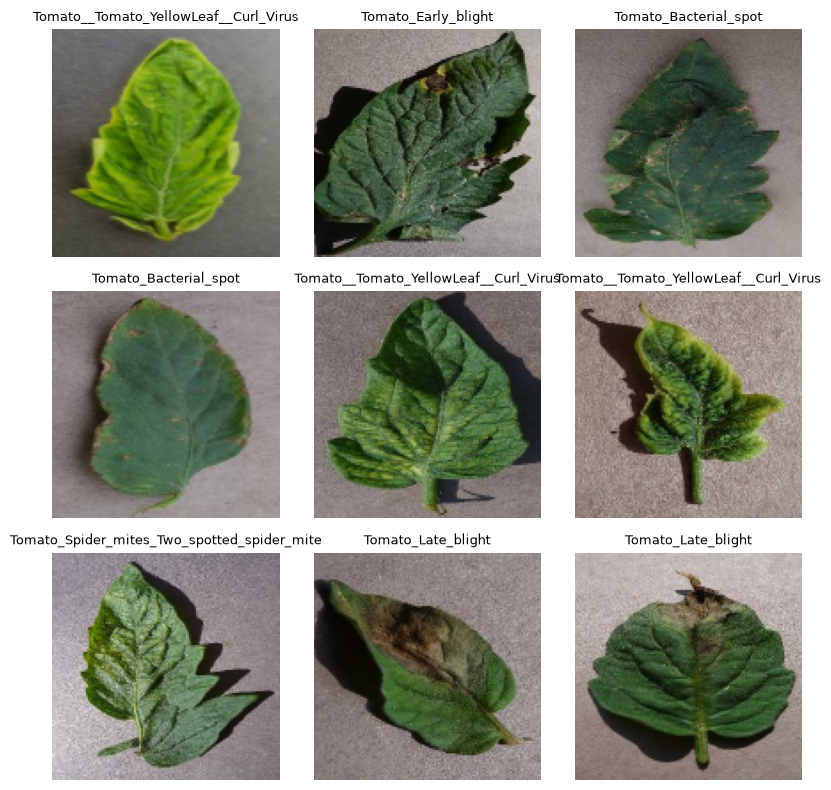

In [5]:
plt.figure(figsize=(8, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(clases[labels[i].numpy()], fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'muestras.png', dpi=150, bbox_inches='tight')
plt.show()

### Preprocesamiento

Las imágenes se redimensionan a 128×128 y se normalizan dentro de cada modelo con `Rescaling(1./255)`. No usamos Data Augmentation: primero queremos una comparación limpia entre arquitecturas.

## Fase 2: Modelado y Entrenamiento

### Modelo MLP

Mantenemos la forma del mejor MLP de la EP1 (512–256–128), pero agregamos Dropout y EarlyStopping. La idea es conservar la misma arquitectura base y cambiar solo lo necesario para que el modelo no sobreajuste. También bajamos el learning rate a 1e-4: con 1e-3 el MLP de 25 millones de parámetros no aprendía en nuestras pruebas.

El MLP aplana la imagen, así que pierde la relación entre píxeles vecinos. Eso es justamente lo que queremos contrastar con la CNN.

In [6]:
modelo_mlp = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255, input_shape=(128, 128, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(len(clases), activation='softmax')
])

modelo_mlp.summary()

/home/kydo/.local/lib/python3.14/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    25,166,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,331,850 (96.63 MB)

 Trainable params: 25,331,850 (96.63 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
modelo_mlp.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
early_stop_mlp = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

checkpoint_mlp = tf.keras.callbacks.ModelCheckpoint(
    MODELS_DIR / 'mlp_ep2.keras',
    monitor='val_loss',
    save_best_only=True
)

inicio_mlp = time.time()
historia_mlp = modelo_mlp.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stop_mlp, checkpoint_mlp]
)
tiempo_mlp = time.time() - inicio_mlp

pd.DataFrame(historia_mlp.history).to_csv(MODELS_DIR / 'history_mlp.csv', index=False)
print(f'Tiempo de entrenamiento MLP: {tiempo_mlp:.1f} s')

Epoch 1/40


/home/kydo/.local/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/401 ━━━━━━━━━━━━━━━━━━━━ 26:49 4s/step - accuracy: 0.0625 - loss: 2.7393

  8/401 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.1055 - loss: 3.4039  

 15/401 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.1313 - loss: 3.0859

 23/401 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.1332 - loss: 2.9475

... (1,864 outputs left out)

389/401 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6440 - loss: 0.9956

396/401 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6439 - loss: 0.9934

401/401 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6440 - loss: 0.9932 - val_accuracy: 0.6927 - val_loss: 0.8722


Tiempo de entrenamiento MLP: 120.1 s


### Graficación de Rendimiento del MLP

Graficamos loss y accuracy para ver si el modelo aprende y si hay sobreajuste.

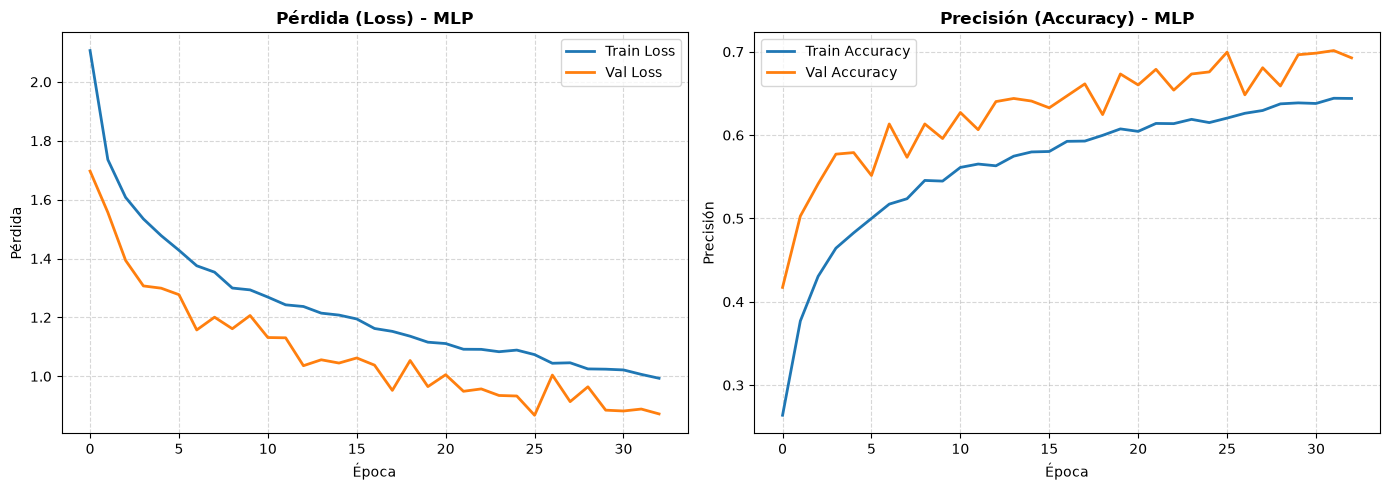

In [9]:
def graficar_rendimiento(historia, nombre_arquitectura):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(historia.history['loss'], label='Train Loss', color='#1f77b4', linewidth=2)
    ax1.plot(historia.history['val_loss'], label='Val Loss', color='#ff7f0e', linewidth=2)
    ax1.set_title(f'Pérdida (Loss) - {nombre_arquitectura}', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Época')
    ax1.set_ylabel('Pérdida')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.5)

    ax2.plot(historia.history['accuracy'], label='Train Accuracy', color='#1f77b4', linewidth=2)
    ax2.plot(historia.history['val_accuracy'], label='Val Accuracy', color='#ff7f0e', linewidth=2)
    ax2.set_title(f'Precisión (Accuracy) - {nombre_arquitectura}', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Época')
    ax2.set_ylabel('Precisión')
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(IMAGES_DIR / f'curvas_{nombre_arquitectura.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()

graficar_rendimiento(historia_mlp, 'MLP')

El MLP aprende, pero se queda atrás. En esta corrida llegó a 71,5% de accuracy y 64,6% de F1 macro, con 76,6% de accuracy en entrenamiento. La brecha es de 5,1 puntos, así que no vemos sobreajuste: el problema es underfitting. Las clases que peor reconoce son Early blight (F1 0,18), Leaf Mold (0,52), Septoria (0,54) y mosaic (0,59). El Dropout ayuda a regularizar, pero no resuelve la pérdida de estructura espacial.

### Modelo CNN

La CNN recibe la imagen como matriz y aprende filtros locales. Usamos tres bloques de convolución con MaxPooling y Dropout, y al final dos capas densas. La idea es que las primeras capas detecten bordes y color, y las más profundas detecten manchas y texturas.

In [10]:
modelo_cnn = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255, input_shape=(128, 128, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', name='conv_1'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', name='conv_2'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu', name='conv_3'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(clases), activation='softmax')
])

modelo_cnn.summary()

/home/kydo/.local/lib/python3.14/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
modelo_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [12]:
early_stop_cnn = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

checkpoint_cnn = tf.keras.callbacks.ModelCheckpoint(
    MODELS_DIR / 'cnn_ep2.keras',
    monitor='val_loss',
    save_best_only=True
)

inicio_cnn = time.time()
historia_cnn = modelo_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stop_cnn, checkpoint_cnn]
)
tiempo_cnn = time.time() - inicio_cnn

pd.DataFrame(historia_cnn.history).to_csv(MODELS_DIR / 'history_cnn.csv', index=False)
print(f'Tiempo de entrenamiento CNN: {tiempo_cnn:.1f} s')

Epoch 1/40


/home/kydo/.local/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/401 ━━━━━━━━━━━━━━━━━━━━ 31:12 5s/step - accuracy: 0.2188 - loss: 2.3041

  4/401 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.1328 - loss: 2.2662 

  7/401 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.1116 - loss: 2.2829

 10/401 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.1406 - loss: 2.2656

... (5,433 outputs left out)

397/401 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9717 - loss: 0.0814

400/401 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9716 - loss: 0.0817

401/401 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9715 - loss: 0.0818 - val_accuracy: 0.9363 - val_loss: 0.1988


Tiempo de entrenamiento CNN: 390.6 s


### Graficación de Rendimiento de la CNN

Graficamos las mismas curvas para la CNN.

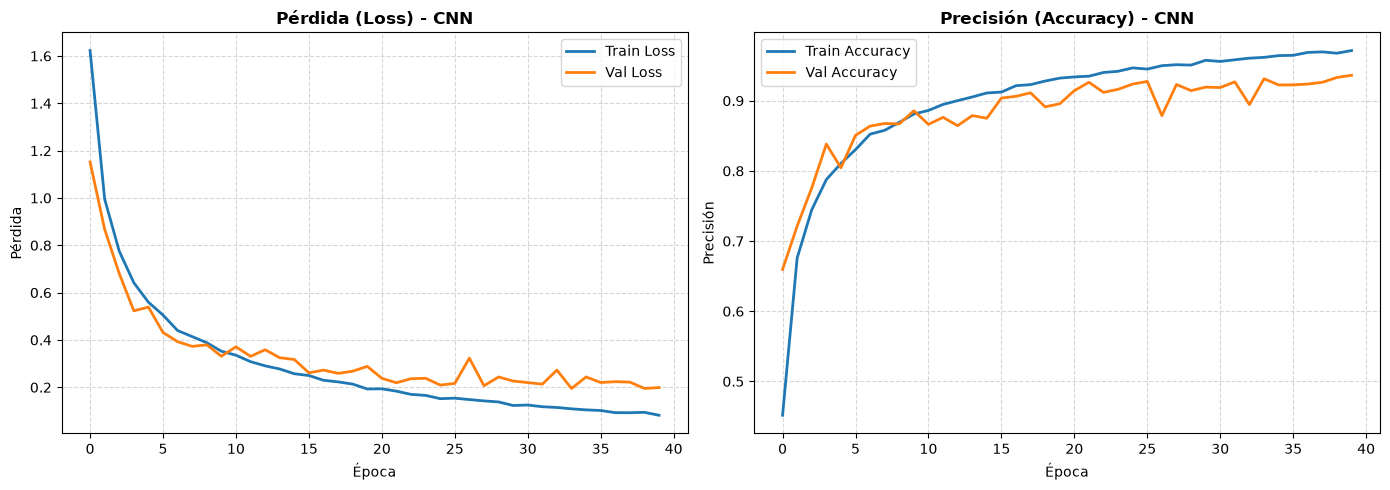

In [13]:
graficar_rendimiento(historia_cnn, 'CNN')

La CNN converge más rápido y llega más lejos: 94,1% de accuracy y 93,2% de F1 macro. La accuracy de entrenamiento es 99,3% y la brecha con test es 5,2 puntos. No vemos un sobreajuste fuerte; la diferencia con el MLP es grande y aparece desde las primeras épocas.

## Fase 3: Evaluación

### Predicciones y Métricas

Evaluamos los dos modelos en el mismo `test_ds`. Usamos accuracy y F1 macro; el F1 macro nos importa porque el dataset está desbalanceado y no queremos que las clases mayoritarias escondan el mal desempeño en las minoritarias.


MLP
Accuracy: 0.7147
F1 macro: 0.6462
Parámetros: 25,331,850
                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot       0.73      0.78      0.76       213
                        Tomato_Early_blight       0.35      0.12      0.18       100
                         Tomato_Late_blight       0.73      0.71      0.72       191
                           Tomato_Leaf_Mold       0.64      0.43      0.52        95
                  Tomato_Septoria_leaf_spot       0.51      0.56      0.54       177
Tomato_Spider_mites_Two_spotted_spider_mite       0.69      0.80      0.74       168
                        Tomato__Target_Spot       0.65      0.73      0.69       141
      Tomato__Tomato_YellowLeaf__Curl_Virus       0.85      0.90      0.87       321
                Tomato__Tomato_mosaic_virus       0.81      0.46      0.59        37
                             Tomato_healthy       0.82      0.92      0.87       159

 

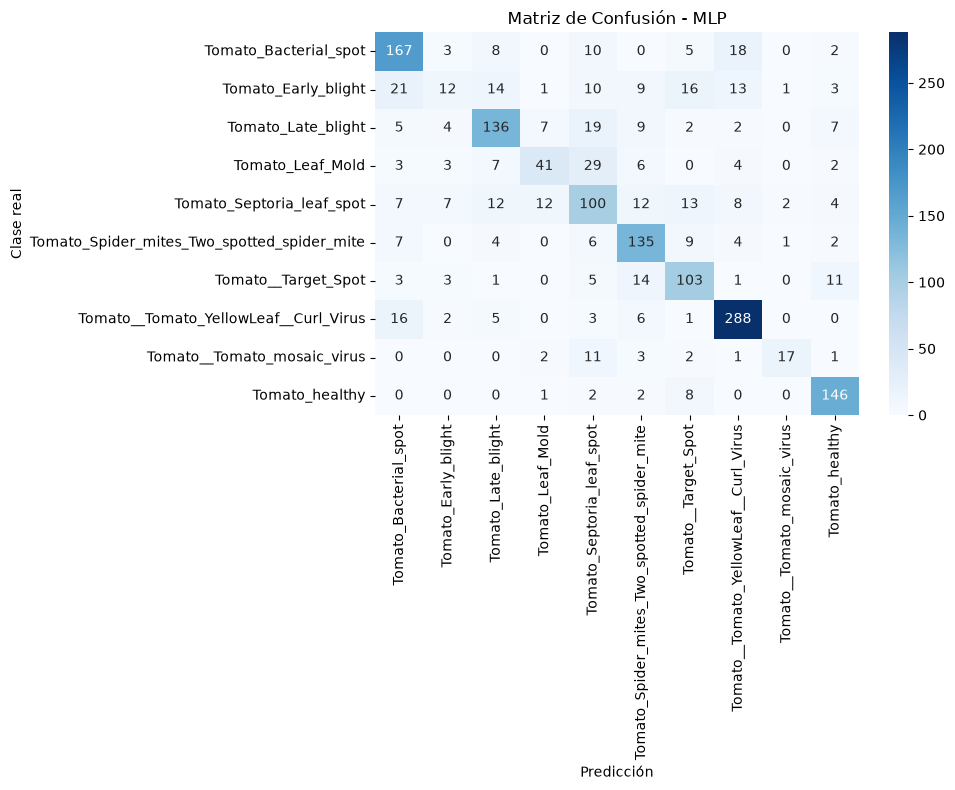


CNN
Accuracy: 0.9413
F1 macro: 0.9320
Parámetros: 3,305,930
                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot       0.92      1.00      0.96       213
                        Tomato_Early_blight       0.82      0.72      0.77       100
                         Tomato_Late_blight       0.91      0.93      0.92       191
                           Tomato_Leaf_Mold       0.98      0.89      0.93        95
                  Tomato_Septoria_leaf_spot       0.93      0.94      0.94       177
Tomato_Spider_mites_Two_spotted_spider_mite       0.95      0.95      0.95       168
                        Tomato__Target_Spot       0.90      0.94      0.92       141
      Tomato__Tomato_YellowLeaf__Curl_Virus       0.99      0.98      0.98       321
                Tomato__Tomato_mosaic_virus       0.97      0.97      0.97        37
                             Tomato_healthy       1.00      0.97      0.99       159

  

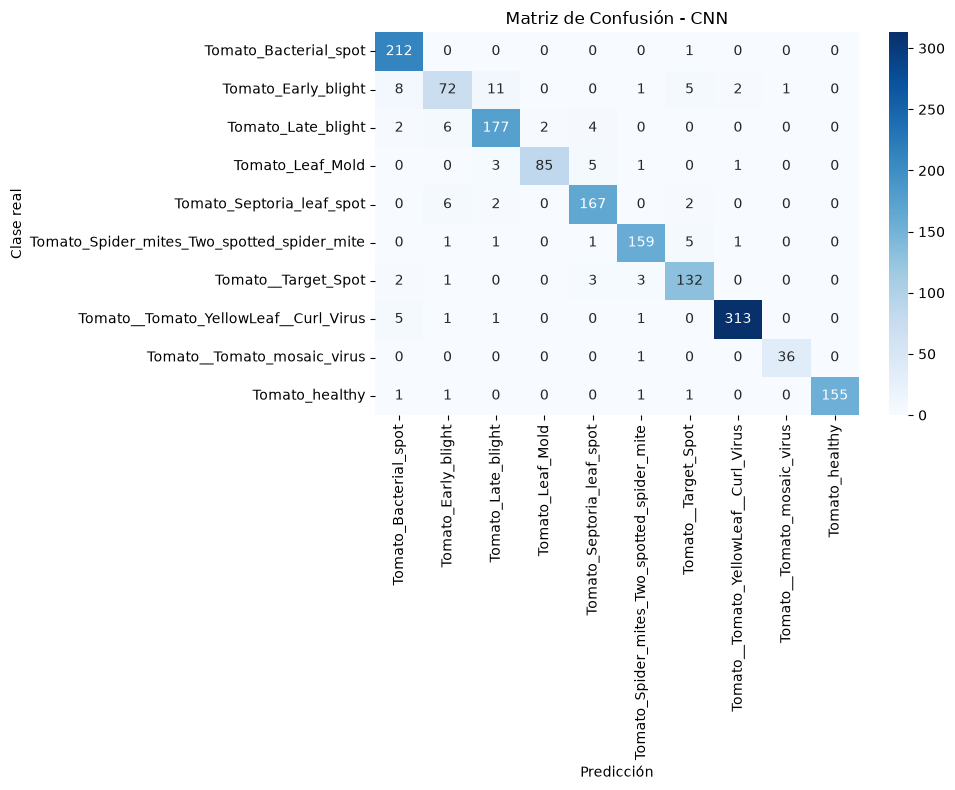

In [14]:
def evaluar_modelo(modelo, nombre):
    y_true = []
    y_pred = []

    for x_batch, y_batch in test_ds:
        preds = modelo.predict(x_batch, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(y_batch.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = (y_true == y_pred).mean()
    f1_macro = f1_score(y_true, y_pred, average='macro')
    params = modelo.count_params()

    print(f'\n{nombre}')
    print(f'Accuracy: {accuracy:.4f}')
    print(f'F1 macro: {f1_macro:.4f}')
    print(f'Parámetros: {params:,}')

    reporte = classification_report(y_true, y_pred, target_names=clases)
    print(reporte)
    with open(MODELS_DIR / f'report_{nombre.lower()}.txt', 'w') as f:
        f.write(reporte)

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=clases, yticklabels=clases)
    plt.xlabel('Predicción')
    plt.ylabel('Clase real')
    plt.title(f'Matriz de Confusión - {nombre}')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.savefig(IMAGES_DIR / f'matriz_{nombre.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()

    return y_true, y_pred, accuracy, f1_macro, params

y_true_mlp, y_pred_mlp, acc_mlp, f1_mlp, params_mlp = evaluar_modelo(modelo_mlp, 'MLP')
y_true_cnn, y_pred_cnn, acc_cnn, f1_cnn, params_cnn = evaluar_modelo(modelo_cnn, 'CNN')

El MLP se queda en 71,5% de accuracy y 64,6% de F1 macro; la CNN llega a 94,1% y 93,2%. La diferencia no es solo de accuracy: el F1 macro muestra que el MLP tiene clases que casi no reconoce, sobre todo Early blight (F1 0,18), Leaf Mold (0,52) y Septoria (0,54). La CNN mejora esas clases (0,77, 0,93 y 0,94), aunque Early blight sigue siendo la más difícil.

### Comparación MLP vs CNN

Para comparar, miramos accuracy, F1 macro, cantidad de parámetros y tiempo de entrenamiento. También revisamos la brecha entre train y test, porque un modelo puede tener buena accuracy y aun así estar memorizando.

MLP
Accuracy test: 0.7147
Accuracy train: 0.7658
Brecha: 0.0510
F1 macro: 0.6462
Parámetros: 25,331,850
Tiempo: 120.1 s

CNN
Accuracy test: 0.9413
Accuracy train: 0.9934
Brecha: 0.0521
F1 macro: 0.9320
Parámetros: 3,305,930
Tiempo: 390.6 s


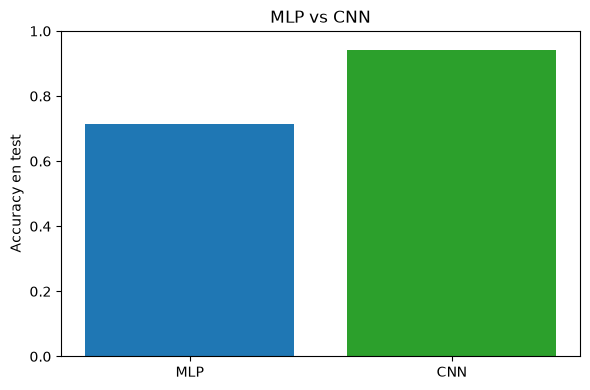

In [15]:
acc_train_mlp = modelo_mlp.evaluate(train_ds, verbose=0)[1]
acc_train_cnn = modelo_cnn.evaluate(train_ds, verbose=0)[1]

print('MLP')
print(f'Accuracy test: {acc_mlp:.4f}')
print(f'Accuracy train: {acc_train_mlp:.4f}')
print(f'Brecha: {acc_train_mlp - acc_mlp:.4f}')
print(f'F1 macro: {f1_mlp:.4f}')
print(f'Parámetros: {params_mlp:,}')
print(f'Tiempo: {tiempo_mlp:.1f} s')

print('\nCNN')
print(f'Accuracy test: {acc_cnn:.4f}')
print(f'Accuracy train: {acc_train_cnn:.4f}')
print(f'Brecha: {acc_train_cnn - acc_cnn:.4f}')
print(f'F1 macro: {f1_cnn:.4f}')
print(f'Parámetros: {params_cnn:,}')
print(f'Tiempo: {tiempo_cnn:.1f} s')

metricas = {
    'mlp': {
        'accuracy_test': float(acc_mlp),
        'f1_macro': float(f1_mlp),
        'accuracy_train': float(acc_train_mlp),
        'brecha': float(acc_train_mlp - acc_mlp),
        'parametros': int(params_mlp),
        'tiempo_entrenamiento_s': float(tiempo_mlp)
    },
    'cnn': {
        'accuracy_test': float(acc_cnn),
        'f1_macro': float(f1_cnn),
        'accuracy_train': float(acc_train_cnn),
        'brecha': float(acc_train_cnn - acc_cnn),
        'parametros': int(params_cnn),
        'tiempo_entrenamiento_s': float(tiempo_cnn)
    }
}
with open(MODELS_DIR / 'metrics.json', 'w') as f:
    json.dump(metricas, f, indent=2)

plt.figure(figsize=(6, 4))
plt.bar(['MLP', 'CNN'], [acc_mlp, acc_cnn], color=['#1f77b4', '#2ca02c'])
plt.ylabel('Accuracy en test')
plt.title('MLP vs CNN')
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'comparacion.png', dpi=150, bbox_inches='tight')
plt.show()

La CNN gana en accuracy y F1 macro, y usa 7,7 veces menos parámetros (3,3 M vs 25,3 M). El costo es el tiempo: 390,6 s frente a 120,1 s. La brecha train-test es parecida (5,2 vs 5,1 puntos), pero el MLP tiene una accuracy de train de 76,6%, así que su problema es underfitting, no sobreajuste.

### Mapas de Características

Mostramos los mapas de las tres capas convolucionales para una imagen de test. En las primeras capas se ven bordes y contrastes; en las profundas aparecen zonas más ligadas a la enfermedad.

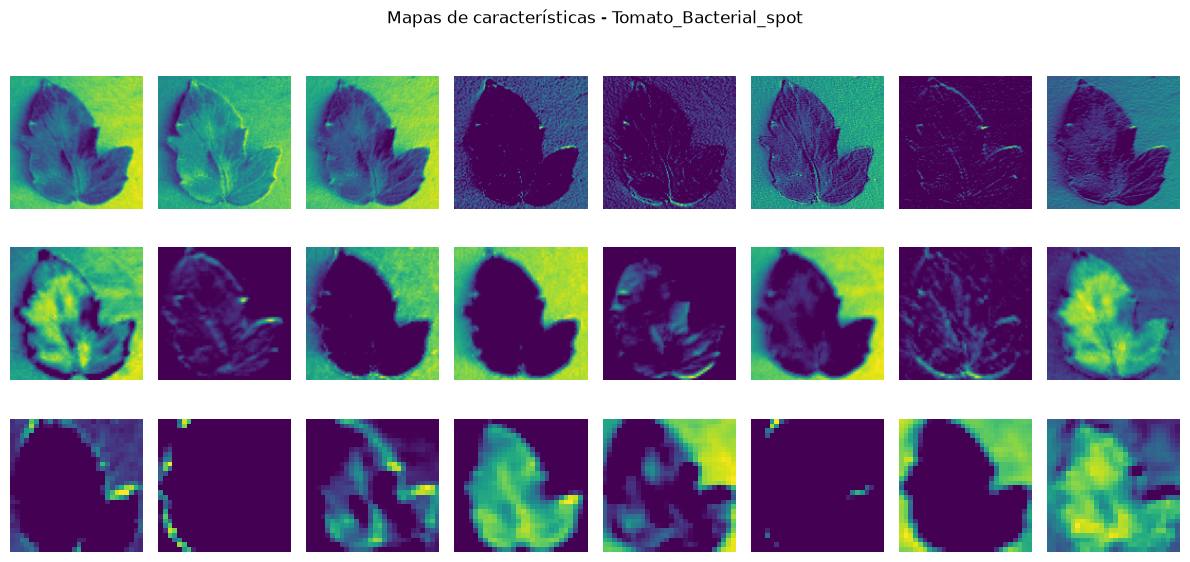

In [16]:
modelo_mapas = tf.keras.Model(
    inputs=modelo_cnn.inputs[0],
    outputs=[
        modelo_cnn.get_layer('conv_1').output,
        modelo_cnn.get_layer('conv_2').output,
        modelo_cnn.get_layer('conv_3').output
    ]
)

for imagenes, etiquetas in test_ds.take(1):
    imagen = imagenes[0:1]
    etiqueta = etiquetas[0].numpy()

salidas = modelo_mapas(imagen)

plt.figure(figsize=(12, 6))
for fila, salida in enumerate(salidas):
    for i in range(8):
        plt.subplot(3, 8, fila * 8 + i + 1)
        plt.imshow(salida[0, :, :, i], cmap='viridis')
        plt.axis('off')
plt.suptitle(f'Mapas de características - {clases[etiqueta]}')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'feature_maps.png', dpi=150, bbox_inches='tight')
plt.show()

### Mapas de Activación (Grad-CAM)

Grad-CAM muestra qué partes de la imagen pesaron más en la predicción. Generamos un mapa por cada clase y también revisamos algunos errores.

In [17]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.Model(
        inputs=model.inputs[0],
        outputs=[model.get_layer(last_conv_layer_name).output, model.outputs[0]]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = int(tf.argmax(predictions[0]))
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

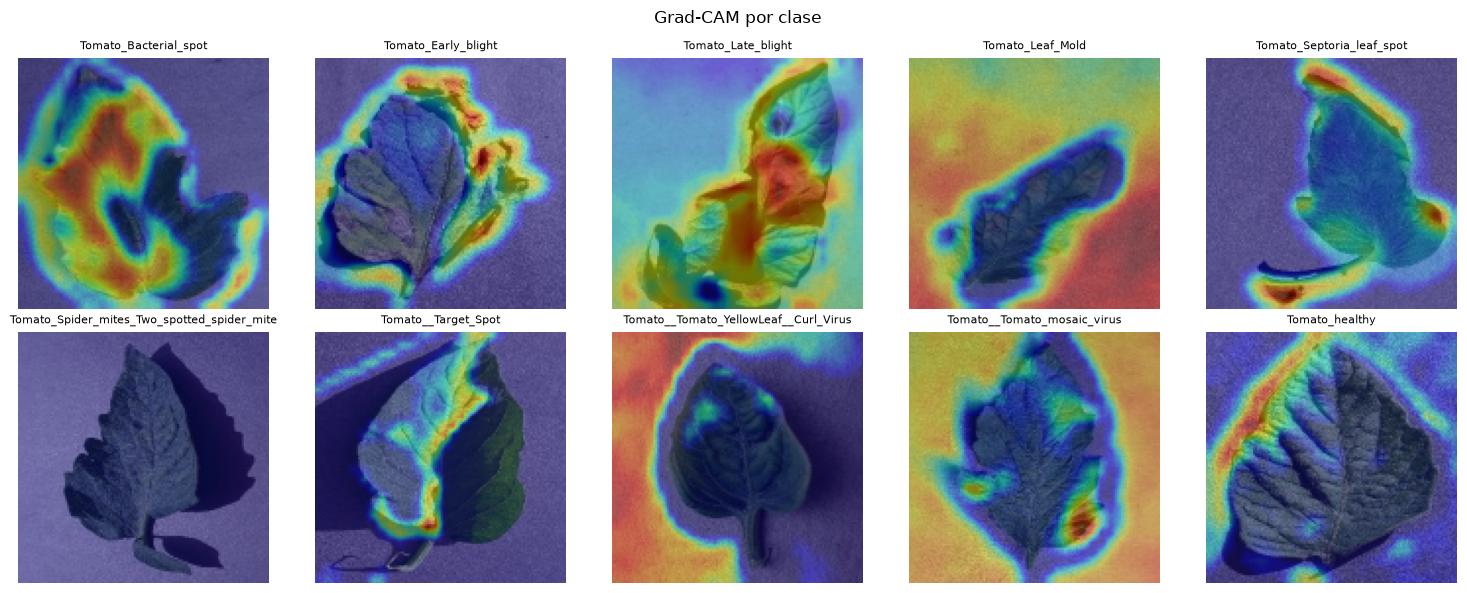

In [18]:
imagenes_test = np.concatenate([x.numpy() for x, y in test_ds], axis=0)
etiquetas_test = np.concatenate([y.numpy() for x, y in test_ds], axis=0)

plt.figure(figsize=(15, 6))
for i, clase in enumerate(clases):
    indices = np.where(etiquetas_test == i)[0]
    if len(indices) == 0:
        continue
    imagen = imagenes_test[indices[0]:indices[0] + 1]
    heatmap = make_gradcam_heatmap(imagen, modelo_cnn, 'conv_3')
    heatmap = tf.image.resize(heatmap[..., np.newaxis], (128, 128)).numpy().squeeze()

    plt.subplot(2, 5, i + 1)
    plt.imshow(imagen[0].astype('uint8'))
    plt.imshow(heatmap, cmap='jet', alpha=0.45)
    plt.title(clase, fontsize=8)
    plt.axis('off')
plt.suptitle('Grad-CAM por clase')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'gradcam_clases.png', dpi=150, bbox_inches='tight')
plt.show()

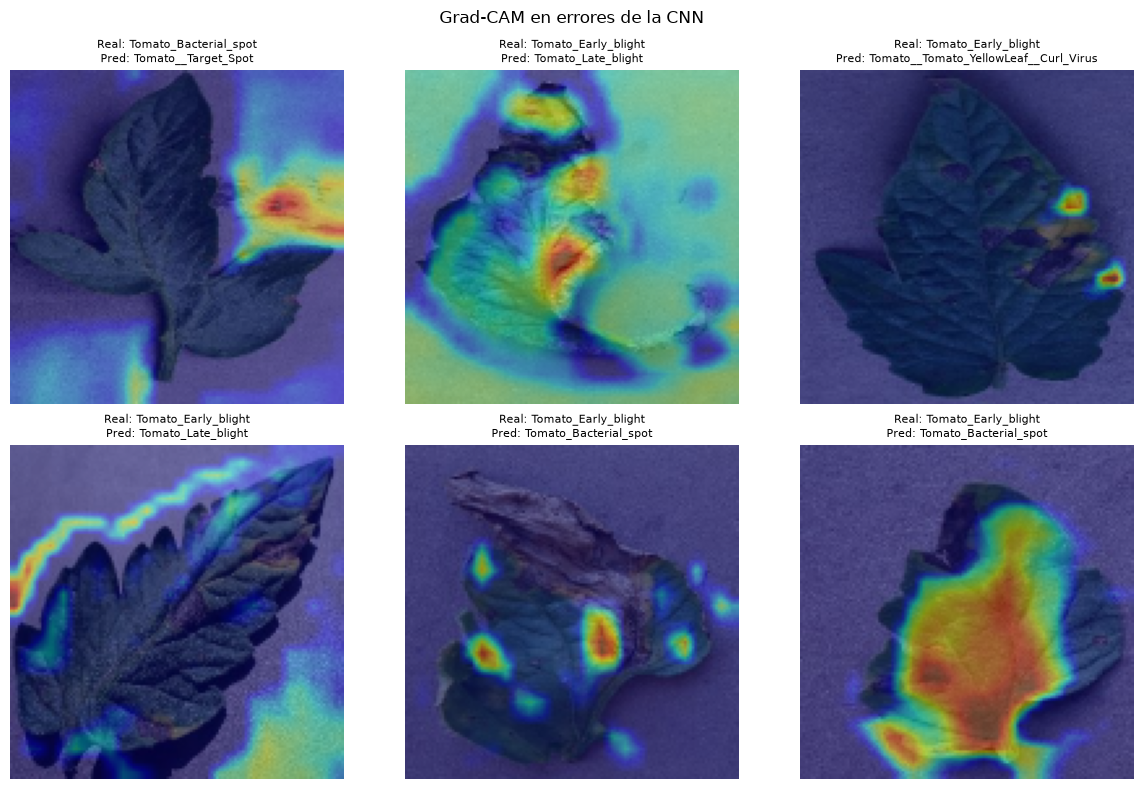

In [19]:
errores = np.where(y_pred_cnn != y_true_cnn)[0]

plt.figure(figsize=(12, 8))
for i, idx in enumerate(errores[:6]):
    imagen = imagenes_test[idx:idx + 1]
    heatmap = make_gradcam_heatmap(imagen, modelo_cnn, 'conv_3')
    heatmap = tf.image.resize(heatmap[..., np.newaxis], (128, 128)).numpy().squeeze()

    plt.subplot(2, 3, i + 1)
    plt.imshow(imagen[0].astype('uint8'))
    plt.imshow(heatmap, cmap='jet', alpha=0.45)
    plt.title(f"Real: {clases[y_true_cnn[idx]]}\nPred: {clases[y_pred_cnn[idx]]}", fontsize=8)
    plt.axis('off')
plt.suptitle('Grad-CAM en errores de la CNN')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'gradcam_errores.png', dpi=150, bbox_inches='tight')
plt.show()

### Análisis de Errores

Revisamos los errores de la CNN para entender qué clases se confunden. También miramos el reporte por clase del MLP, que es donde más se nota la diferencia.

In [20]:
print("Errores CNN:", len(errores), "de", len(y_true_cnn))
print("Errores MLP:", len(np.where(y_pred_mlp != y_true_mlp)[0]), "de", len(y_true_mlp))

cm_cnn = confusion_matrix(y_true_cnn, y_pred_cnn)
np.fill_diagonal(cm_cnn, 0)
indices = np.dstack(np.unravel_index(np.argsort(cm_cnn.ravel())[::-1][:5], cm_cnn.shape))[0]

print("\nConfusiones principales CNN:")
for real, pred in indices:
    if cm_cnn[real, pred] > 0:
        print(f"{clases[real]} -> {clases[pred]}: {cm_cnn[real, pred]}")

Errores CNN: 94 de 1602
Errores MLP: 457 de 1602

Confusiones principales CNN:
Tomato_Early_blight -> Tomato_Late_blight: 11
Tomato_Early_blight -> Tomato_Bacterial_spot: 8
Tomato_Late_blight -> Tomato_Early_blight: 6
Tomato_Septoria_leaf_spot -> Tomato_Early_blight: 6
Tomato__Tomato_YellowLeaf__Curl_Virus -> Tomato_Bacterial_spot: 5


La CNN se equivoca sobre todo en Early blight: 11 casos van a Late blight y 8 a Bacterial spot. También hay 6 casos de Late blight que terminan en Early blight y 6 de Septoria que terminan en Early blight; además, 5 imágenes de YellowLeaf Curl se clasifican como Bacterial spot. Son clases con lesiones parecidas, así que el error tiene sentido. El MLP falla mucho más: 457 errores frente a 94 de la CNN, y su F1 macro queda muy por debajo.

Reconocemos varias limitaciones. Las imágenes son de laboratorio, con hoja centrada y fondo uniforme, así que el modelo podría fallar en fotos de campo. El dataset está desbalanceado y tiene clases con muy pocas imágenes, como mosaic. Usamos una sola semilla y no hicimos Data Augmentation ni validación externa. El test es una partición estratificada 80/10/10 del mismo dataset, no un conjunto externo.

Aun así, la comparación deja una conclusión clara: la CNN aprovecha mejor la estructura espacial y logra 94,1% de accuracy y 93,2% de F1 macro, frente a 71,5% y 64,6% del MLP, con menos parámetros. El MLP no sobreajusta, pero se queda corto: su accuracy de entrenamiento también es baja. Eso muestra que el problema no es solo regularización, sino representación.

Como mejoras futuras proponemos Data Augmentation, `class_weight` para las clases minoritarias, repetir con tres semillas, usar GlobalAveragePooling para reducir parámetros y probar transfer learning.